# Dependent uncertainty and proper forecast scores

Family 35. Residual tests state their null hypothesis. Block bootstrap and HAC covariance target dependence-aware uncertainty under stationarity assumptions; neither fixes a misspecified forecast.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 35: proper scores, residual diagnostics and block uncertainty."""
import numpy as np
from convexity.math import diagnostics

rng = np.random.default_rng(3500)
innovations = rng.normal(size=500)
series = np.zeros(500)
for t in range(1, len(series)):
    series[t] = .7*series[t-1]+innovations[t]
print('Autocorrelation test:', diagnostics.residual_test(series))
print('Unit-root test:', diagnostics.stationarity_test(series, lags=2))
print('Weighted CRPS:', diagnostics.crps([-2., 1., 3.], 2., weights=[.1, .3, .6]))
bootstrap = diagnostics.block_bootstrap(np.mean, series, block_length=15, draws=499, rng=rng)
print('Block mean interval:', bootstrap.lower, bootstrap.upper)
print('HAC mean variance:', diagnostics.hac_mean_covariance(series, lags=14))
print('Holm adjusted:', diagnostics.adjust_pvalues([.01, .04, .03]))


Autocorrelation test: TestResult(statistic=array([276.02825956, 579.29408723, 612.66424099]), pvalue=array([5.50971241e-062, 6.01591717e-123, 3.40328809e-125]), method='ljung_box', null='no autocorrelation through each supplied lag', details=mappingproxy({}))
Unit-root test: TestResult(statistic=array(-7.62681905), pvalue=array(2.05819888e-11), method='ADF', null='unit root', details=mappingproxy({'lags': 2, 'nobs': 497}))
Weighted CRPS: 0.55
Block mean interval: -0.3580914635848217 0.2689323642543271
HAC mean variance: [[0.02455124]]
Holm adjusted: [0.03 0.06 0.06]


## Dependence changes mean uncertainty

IID resampling misses serial dependence in this AR sample. Larger blocks preserve more of that dependence, with greater Monte Carlo variability. Scores are evaluated on a supplied probability law, independently of resampling uncertainty.

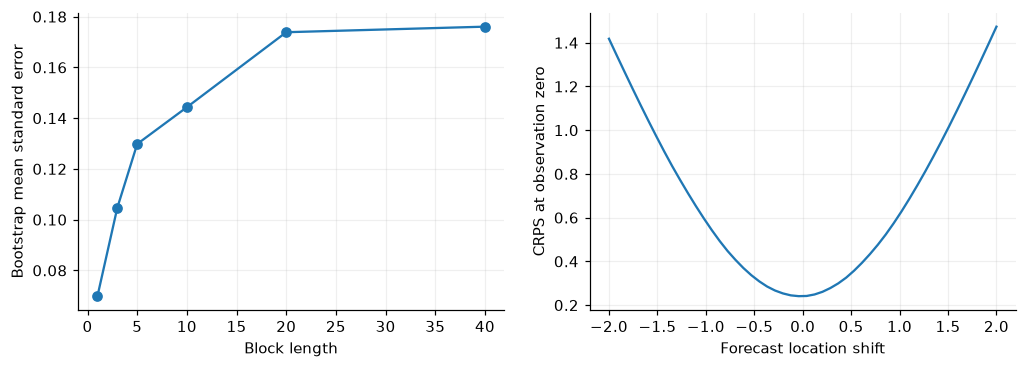

In [3]:
blocks = [1, 3, 5, 10, 20, 40]
standard_errors = []
for block in blocks:
    result = diagnostics.block_bootstrap(np.mean, series, block_length=block, draws=400, rng=np.random.default_rng(3500+block))
    standard_errors.append(result.samples.std(ddof=1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(blocks, standard_errors, marker='o'); axes[0].set(xlabel='Block length', ylabel='Bootstrap mean standard error')
ensemble = np.random.default_rng(3501).normal(size=1000)
shifts = np.linspace(-2, 2, 50)
scores = [diagnostics.crps(ensemble+shift, 0.) for shift in shifts]
axes[1].plot(shifts, scores); axes[1].set(xlabel='Forecast location shift', ylabel='CRPS at observation zero'); plt.show()

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.